In [1]:
import pandas as pd
import numpy as np

In [2]:
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.6
NumPy version: 2.5.3


In [3]:
df = pd.read_csv("../data/Churn_Modelling.csv")


In [4]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
df.shape

(10000, 14)

In [6]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [8]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [9]:
df["Geography"].value_counts()


Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [10]:
df["Gender"].value_counts()


Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [11]:
df["Exited"].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [12]:
df["Exited"].value_counts(normalize=True) * 100

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64

In [13]:
df.isnull().sum()


RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.nunique()

RowNumber          10000
CustomerId         10000
Surname             2932
CreditScore          460
Geography              3
Gender                 2
Age                   70
Tenure                11
Balance             6382
NumOfProducts          4
HasCrCard              2
IsActiveMember         2
EstimatedSalary     9999
Exited                 2
dtype: int64

In [16]:
pd.crosstab(df["Geography"], df["Exited"])

Exited,0,1
Geography,,
France,4204,810
Germany,1695,814
Spain,2064,413


In [17]:
pd.crosstab(
    df["Geography"],
    df["Exited"],
    normalize="index"
) * 100

Exited,0,1
Geography,,
France,83.845233,16.154767
Germany,67.556796,32.443204
Spain,83.326605,16.673395


In [18]:
pd.crosstab(df["Gender"], df["Exited"])

Exited,0,1
Gender,,
Female,3404,1139
Male,4559,898


In [19]:
pd.crosstab(
    df["Gender"],
    df["Exited"],
    normalize="index"
) * 100

Exited,0,1
Gender,,
Female,74.928461,25.071539
Male,83.544072,16.455928


In [20]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 29, 39, 49, 59, 100],
    labels=["18-29", "30-39", "40-49", "50-59", "60+"]
)

In [21]:
df["AgeGroup"].value_counts().sort_index()

AgeGroup
18-29    1641
30-39    4346
40-49    2618
50-59     869
60+       526
Name: count, dtype: int64

In [22]:
pd.crosstab(
    df["AgeGroup"],
    df["Exited"],
    normalize="index"
) * 100


Exited,0,1
AgeGroup,,
18-29,92.443632,7.556368
30-39,89.116429,10.883571
40-49,69.213140,30.786860
50-59,43.958573,56.041427
60+,72.053232,27.946768


In [23]:
df["AgeGroup"].value_counts()

AgeGroup
30-39    4346
40-49    2618
18-29    1641
50-59     869
60+       526
Name: count, dtype: int64

In [24]:
pd.crosstab(
    df["AgeGroup"],
    df["Exited"],
    normalize="index"
) * 100

Exited,0,1
AgeGroup,,
18-29,92.443632,7.556368
30-39,89.116429,10.883571
40-49,69.213140,30.786860
50-59,43.958573,56.041427
60+,72.053232,27.946768


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

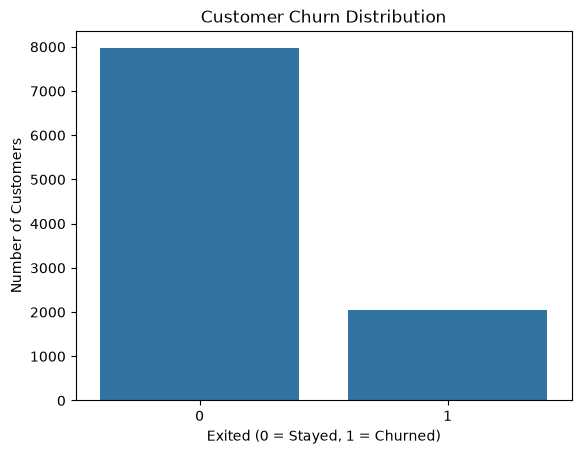

In [26]:
sns.countplot(x="Exited", data=df)

plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Number of Customers")

plt.show()

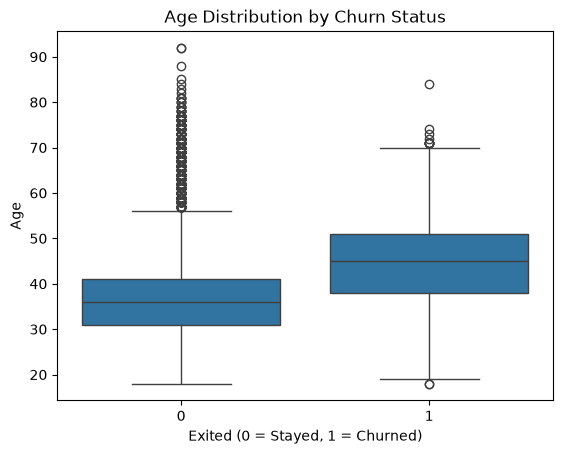

In [27]:
sns.boxplot(x="Exited", y="Age", data=df)

plt.title("Age Distribution by Churn Status")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Age")

plt.show()


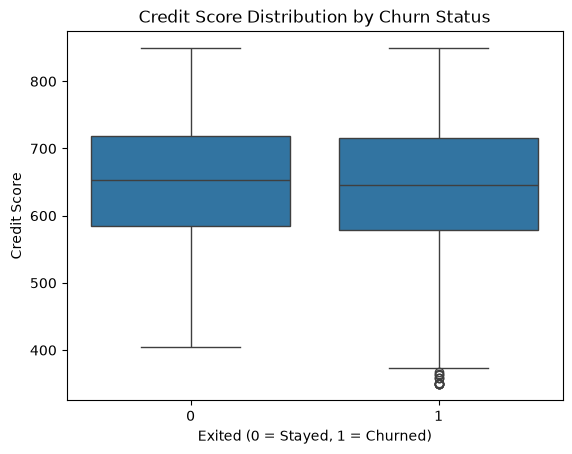

In [28]:
sns.boxplot(x="Exited", y="CreditScore", data=df)

plt.title("Credit Score Distribution by Churn Status")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Credit Score")

plt.show()

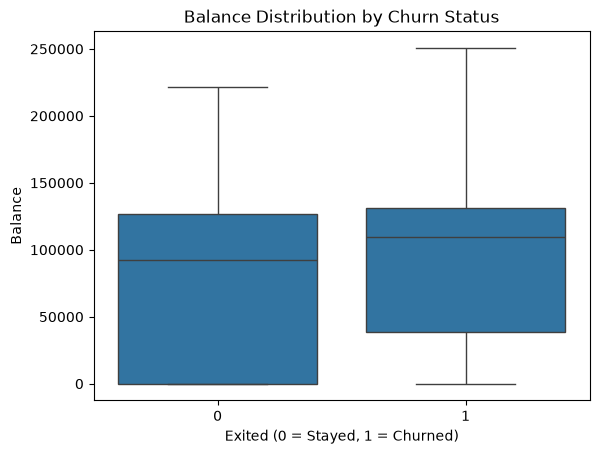

In [29]:
sns.boxplot(x="Exited", y="Balance", data=df)

plt.title("Balance Distribution by Churn Status")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Balance")

plt.show()

In [31]:
df[df["Balance"] == 0]["Exited"].value_counts()

Exited
0    3117
1     500
Name: count, dtype: int64

In [32]:
pd.crosstab(
    df["NumOfProducts"],
    df["Exited"],
    normalize="index"
) * 100

Exited,0,1
NumOfProducts,,
1,72.285602,27.714398
2,92.418301,7.581699
3,17.293233,82.706767
4,0.000000,100.000000


In [33]:
df["NumOfProducts"].value_counts().sort_index()

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

In [34]:
pd.crosstab(
    df["IsActiveMember"],
    df["Exited"],
    normalize="index"
) * 100

Exited,0,1
IsActiveMember,,
0,73.149103,26.850897
1,85.730926,14.269074


In [36]:
pd.crosstab(
    df["HasCrCard"],
    df["Exited"],
    normalize="index"
) * 100

Exited,0,1
HasCrCard,,
0,79.185059,20.814941
1,79.815734,20.184266


In [37]:
pd.crosstab(
    df["Tenure"],
    df["Exited"],
    normalize="index"
) * 100

Exited,0,1
Tenure,,
0,76.997579,23.002421
1,77.584541,22.415459
2,80.820611,19.179389
3,78.889990,21.110010
4,79.474216,20.525784
5,79.347826,20.652174
6,79.731127,20.268873
7,82.782101,17.217899
8,80.780488,19.219512


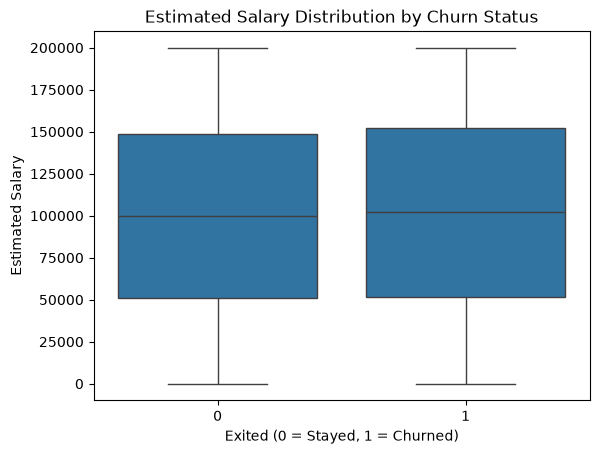

In [38]:
sns.boxplot(x="Exited", y="EstimatedSalary", data=df)

plt.title("Estimated Salary Distribution by Churn Status")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Estimated Salary")

plt.show()

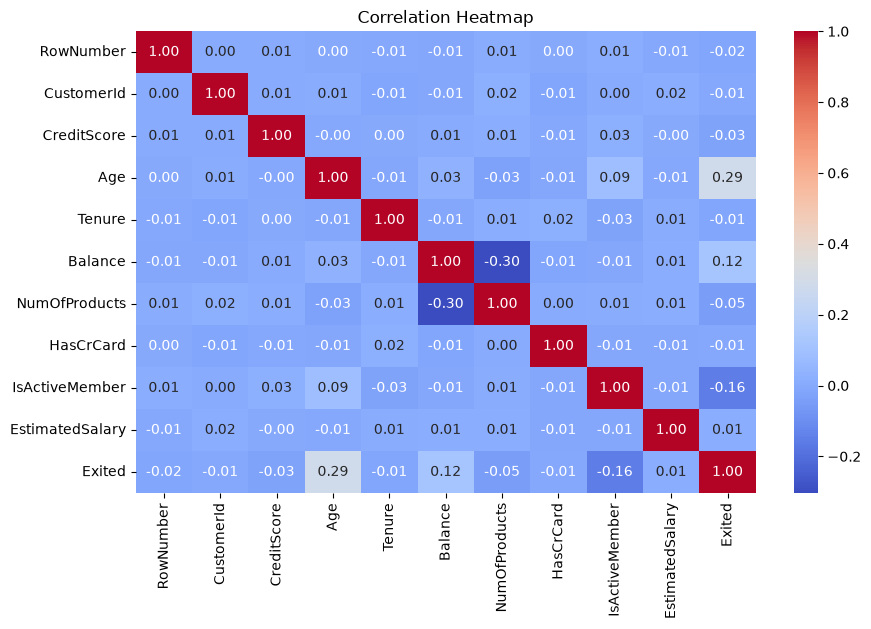

In [39]:
plt.figure(figsize=(10, 6))

corr = df.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [40]:
numeric_cols = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"{col}: {len(outliers)} outliers")

CreditScore: 15 outliers
Age: 359 outliers
Tenure: 0 outliers
Balance: 0 outliers
NumOfProducts: 60 outliers
EstimatedSalary: 0 outliers


In [41]:
Q1 = df["CreditScore"].quantile(0.25)
Q3 = df["CreditScore"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

df[
    (df["CreditScore"] < lower_bound) |
    (df["CreditScore"] > upper_bound)
][["CreditScore", "Age", "Balance", "NumOfProducts", "Exited"]]

Lower Bound: 383.0
Upper Bound: 919.0


,CreditScore,Age,Balance,NumOfProducts,Exited
7,376,29,115046.74,4,1
942,376,46,0.00,1,1
1193,363,28,146098.43,3,1
1405,359,44,128747.69,1,1
1631,350,54,152677.48,1,1
1838,350,39,109733.20,2,1
1962,358,52,143542.36,3,1
2473,351,57,163146.46,1,1
2579,365,30,127760.07,1,1
8154,367,42,93608.28,1,1


In [42]:
Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 32.0
Q3: 44.0
IQR: 12.0
Lower Bound: 14.0
Upper Bound: 62.0


In [43]:
Q1 = df["NumOfProducts"].quantile(0.25)
Q3 = df["NumOfProducts"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 1.0
Q3: 2.0
IQR: 1.0
Lower Bound: -0.5
Upper Bound: 3.5


In [44]:
(df["EstimatedSalary"] == 0).sum()

np.int64(0)

In [45]:
df["BalanceSalaryRatio"] = df["Balance"] / df["EstimatedSalary"]

In [46]:
df[["Balance", "EstimatedSalary", "BalanceSalaryRatio"]].head()

,Balance,EstimatedSalary,BalanceSalaryRatio
0,0.00,101348.88,0.000000
1,83807.86,112542.58,0.744677
2,159660.80,113931.57,1.401375
3,0.00,93826.63,0.000000
4,125510.82,79084.10,1.587055


In [48]:
df["BalanceSalaryRatio"].describe()

count    10000.000000
mean         3.878703
std        108.337260
min          0.000000
25%          0.000000
50%          0.747002
75%          1.514022
max      10614.655440
Name: BalanceSalaryRatio, dtype: float64

In [50]:
df[
    ["Balance", "EstimatedSalary", "BalanceSalaryRatio"]
].sort_values(
    "BalanceSalaryRatio",
    ascending=False
).head(10)

,Balance,EstimatedSalary,BalanceSalaryRatio
2362,122917.71,11.58,10614.655440
9010,121669.93,91.75,1326.102779
7565,105355.81,123.07,856.064110
8722,87619.29,143.34,611.268941
1462,103560.57,236.45,437.980842
3446,87374.88,247.36,353.229625
2046,120018.86,343.38,349.521987
6956,180614.04,523.00,345.342333
5120,141462.13,440.20,321.358769
195,174790.15,600.36,291.142231


In [51]:
df.groupby("Exited")["BalanceSalaryRatio"].describe()

,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0,7963.0,2.478339,14.803568,0.0,0.000000,0.703392,1.446481,611.268941
1,2037.0,9.352977,238.215765,0.0,0.284769,0.887100,1.820143,10614.655440


In [52]:
df["LogBalanceSalaryRatio"] = np.log1p(df["BalanceSalaryRatio"])

In [53]:
df[
    ["BalanceSalaryRatio", "LogBalanceSalaryRatio"]
].describe()

,BalanceSalaryRatio,LogBalanceSalaryRatio
count,10000.000000,10000.000000
mean,3.878703,0.657692
std,108.337260,0.773652
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.747002,0.557901
75%,1.514022,0.921884
max,10614.655440,9.270085


In [54]:
df.groupby("Exited")["LogBalanceSalaryRatio"].describe()

,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0,7963.0,0.624523,0.757382,0.0,0.000000,0.532621,0.894651,6.417172
1,2037.0,0.787355,0.821655,0.0,0.250579,0.635041,1.036787,9.270085


In [55]:
df["ProductDensity"] = (
    df["NumOfProducts"] / (df["Tenure"] + 1)
)

In [56]:
df[
    ["NumOfProducts", "Tenure", "ProductDensity"]
].head(10)

,NumOfProducts,Tenure,ProductDensity
0,1,2,0.333333
1,1,1,0.500000
2,3,8,0.333333
3,2,1,1.000000
4,1,2,0.333333
5,2,8,0.222222
6,2,7,0.250000
7,4,4,0.800000
8,2,4,0.400000
9,1,2,0.333333


In [57]:
df["AgeTenureInteraction"] = df["Age"] * (df["Tenure"] + 1)

df["ActiveProductInteraction"] = (
    df["IsActiveMember"] * df["NumOfProducts"]
)

In [58]:
from sklearn.model_selection import train_test_split

X = df[
    [
        "CreditScore",
        "Geography",
        "Gender",
        "Age",
        "Tenure",
        "Balance",
        "NumOfProducts",
        "HasCrCard",
        "IsActiveMember",
        "EstimatedSalary",
        "LogBalanceSalaryRatio",
        "ProductDensity",
        "AgeTenureInteraction",
        "ActiveProductInteraction"
    ]
]

y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (8000, 14)
Testing: (2000, 14)


In [59]:
categorical_features = [
    "Geography",
    "Gender"
]

In [60]:
numerical_features = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "LogBalanceSalaryRatio",
    "ProductDensity",
    "AgeTenureInteraction",
    "ActiveProductInteraction"
]

In [62]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

In [63]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['CreditScore','Geography','Gender',...,'ProductDensity', 'AgeTenureInteraction','ActiveProductInteraction']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specify

In [64]:
y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.7095
Precision: 0.3836898395721925
Recall: 0.7051597051597052
F1 Score: 0.49696969696969695
ROC-AUC: 0.7749706563265883

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1593
           1       0.38      0.71      0.50       407

    accuracy                           0.71      2000
   macro avg       0.64      0.71      0.65      2000
weighted avg       0.80      0.71      0.73      2000



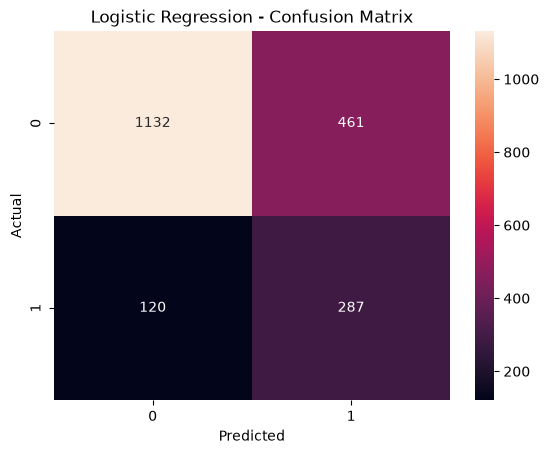

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [67]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=None,
                min_samples_split=5,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['CreditScore','Geography','Gender',...,'ProductDensity', 'AgeTenureInteraction','ActiveProductInteraction']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specify

In [68]:
y_pred_rf = random_forest_model.predict(X_test)

y_prob_rf = (
    random_forest_model
    .predict_proba(X_test)[:, 1]
)

In [69]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.8355
Precision: 0.5886363636363636
Recall: 0.6363636363636364
F1 Score: 0.6115702479338843
ROC-AUC: 0.8561319408777036

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.89      0.90      1593
           1       0.59      0.64      0.61       407

    accuracy                           0.84      2000
   macro avg       0.75      0.76      0.75      2000
weighted avg       0.84      0.84      0.84      2000



In [70]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingClassifier(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

gradient_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['CreditScore','Geography','Gender',...,'ProductDensity', 'AgeTenureInteraction','ActiveProductInteraction']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specify

In [71]:
y_pred_gb = gradient_model.predict(X_test)

y_prob_gb = (
    gradient_model
    .predict_proba(X_test)[:, 1]
)

print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:", f1_score(y_test, y_pred_gb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_gb))

Accuracy: 0.869
Precision: 0.7843137254901961
Recall: 0.4914004914004914
F1 Score: 0.6042296072507553
ROC-AUC: 0.8693585727484032


In [72]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_gb)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_gb)
    ],
    "F1": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_gb)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_gb)
    ]
})

results.sort_values(
    "ROC-AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
2,Gradient Boosting,0.8690,0.784314,0.491400,0.60423,0.869359
1,Random Forest,0.8355,0.588636,0.636364,0.61157,0.856132
0,Logistic Regression,0.7095,0.383690,0.705160,0.49697,0.774971


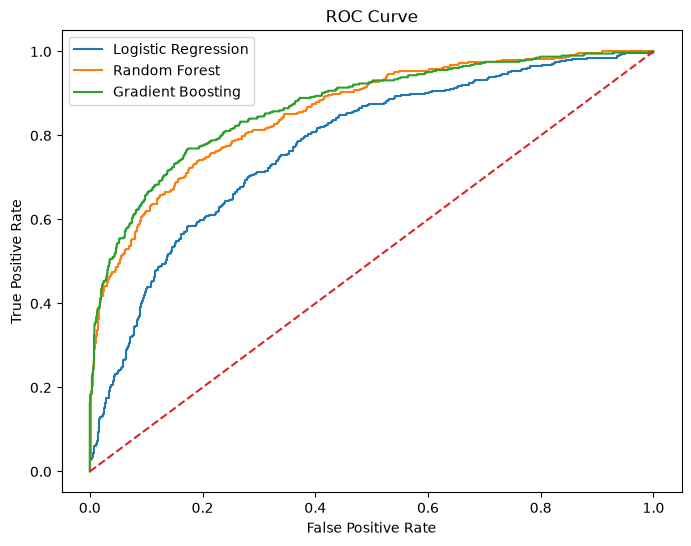

In [73]:
from sklearn.metrics import roc_curve

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_prob_gb)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label="Logistic Regression"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label="Random Forest"
)

plt.plot(
    fpr_gb,
    tpr_gb,
    label="Gradient Boosting"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [74]:
results.sort_values(
    "ROC-AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
2,Gradient Boosting,0.8690,0.784314,0.491400,0.60423,0.869359
1,Random Forest,0.8355,0.588636,0.636364,0.61157,0.856132
0,Logistic Regression,0.7095,0.383690,0.705160,0.49697,0.774971


In [76]:
best_model = gradient_model

risk_probability = best_model.predict_proba(X_test)[:, 1]

risk_df = X_test.copy()

risk_df["ActualExited"] = y_test.values
risk_df["ChurnProbability"] = risk_probability

risk_df["RiskCategory"] = pd.cut(
    risk_df["ChurnProbability"],
    bins=[0, 0.30, 0.60, 1.0],
    labels=["Low Risk", "Medium Risk", "High Risk"],
    include_lowest=True
)

risk_df.head(10)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,LogBalanceSalaryRatio,ProductDensity,AgeTenureInteraction,ActiveProductInteraction,ActualExited,ChurnProbability,RiskCategory
5702,585,France,Male,36,7,0.00,2,1,0,94283.09,0.000000,0.250000,288,0,0,0.022996,Low Risk
3667,525,Germany,Male,33,4,131023.76,2,0,0,55072.93,1.217608,0.400000,165,0,0,0.085350,Low Risk
1617,557,Spain,Female,40,4,0.00,2,0,1,105433.53,0.000000,0.400000,200,2,0,0.039467,Low Risk
5673,639,Spain,Male,34,5,139393.19,2,0,0,33950.08,1.630383,0.333333,204,0,0,0.046297,Low Risk
4272,640,Spain,Female,34,3,77826.80,1,1,1,168544.85,0.379639,0.250000,136,1,0,0.114484,Low Risk
8270,559,Spain,Male,34,0,0.00,1,1,0,182988.94,0.000000,1.000000,34,0,0,0.172367,Low Risk
7079,595,Germany,Male,30,9,130682.11,2,1,1,57862.88,1.181261,0.200000,300,2,0,0.061221,Low Risk
5295,706,Germany,Female,29,6,185544.36,1,1,0,171037.63,0.734681,0.142857,203,0,0,0.279881,Low Risk
845,505,France,Male,49,7,80001.23,1,0,0,135180.11,0.464873,0.125000,392,0,0,0.501983,Medium Risk
5311,714,France,Female,40,0,0.00,2,1,0,62762.12,0.000000,2.000000,40,0,0,0.073832,Low Risk


In [77]:
risk_df["RiskCategory"].value_counts()

RiskCategory
Low Risk       1579
Medium Risk     238
High Risk       183
Name: count, dtype: int64

In [78]:
model = best_model.named_steps["model"]
processor = best_model.named_steps["preprocessor"]

feature_names = processor.get_feature_names_out()

importance = model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
1,num__Age,0.388666
4,num__NumOfProducts,0.286470
3,num__Balance,0.066349
6,num__IsActiveMember,0.064212
11,num__ActiveProductInteraction,0.062356
13,cat__Geography_Germany,0.050149
8,num__LogBalanceSalaryRatio,0.024344
0,num__CreditScore,0.016475
7,num__EstimatedSalary,0.013661
10,num__AgeTenureInteraction,0.007476


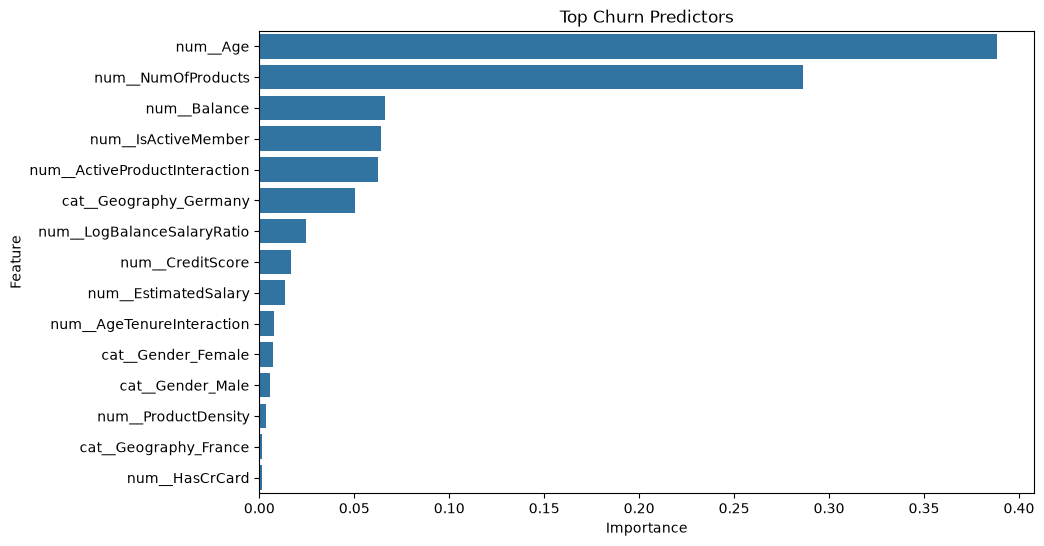

In [79]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top Churn Predictors")
plt.show()

In [80]:
import joblib

best_model = gradient_model

joblib.dump(
    best_model,
    "../models/bank_churn_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [81]:
import os

print(
    os.path.exists(
        "../models/bank_churn_model.pkl"
    )
)

True


In [82]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50]

for threshold in thresholds:

    y_pred_threshold = (
        y_prob_gb >= threshold
    ).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_score(y_test, y_pred_threshold):.3f} | "
        f"Recall: {recall_score(y_test, y_pred_threshold):.3f} | "
        f"F1: {f1_score(y_test, y_pred_threshold):.3f}"
    )

Threshold: 0.30 | Precision: 0.629 | Recall: 0.651 | F1: 0.640
Threshold: 0.35 | Precision: 0.669 | Recall: 0.612 | F1: 0.639
Threshold: 0.40 | Precision: 0.708 | Recall: 0.555 | F1: 0.623
Threshold: 0.45 | Precision: 0.748 | Recall: 0.518 | F1: 0.612
Threshold: 0.50 | Precision: 0.784 | Recall: 0.491 | F1: 0.604


In [83]:
FINAL_THRESHOLD = 0.30

y_pred_final = (
    y_prob_gb >= FINAL_THRESHOLD
).astype(int)

In [84]:
print("Final Accuracy:",
      accuracy_score(y_test, y_pred_final))

print("Final Precision:",
      precision_score(y_test, y_pred_final))

print("Final Recall:",
      recall_score(y_test, y_pred_final))

print("Final F1:",
      f1_score(y_test, y_pred_final))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_gb))

Final Accuracy: 0.851
Final Precision: 0.6294536817102138
Final Recall: 0.6511056511056511
Final F1: 0.6400966183574879
ROC-AUC: 0.8693585727484032


In [85]:
from sklearn.metrics import confusion_matrix

cm_final = confusion_matrix(
    y_test,
    y_pred_final
)

print(cm_final)

[[1437  156]
 [ 142  265]]


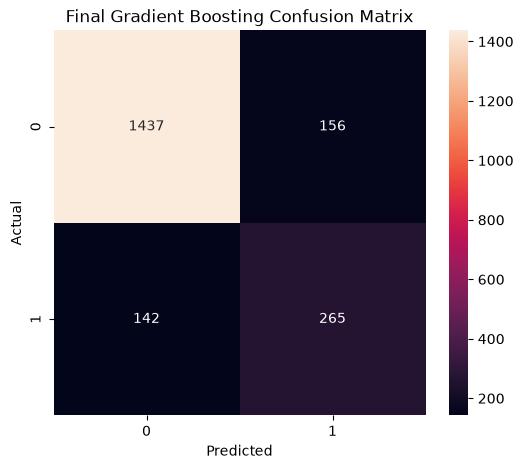

In [86]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d"
)

plt.title("Final Gradient Boosting Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [87]:
import joblib

joblib.dump(
    best_model,
    "../models/bank_churn_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [88]:
import os

print(
    os.path.exists(
        "../models/bank_churn_model.pkl"
    )
)

True


In [89]:
final_risk_df = X_test.copy()

final_risk_df["ActualExited"] = y_test.values

final_risk_df["ChurnProbability"] = y_prob_gb

final_risk_df["RiskCategory"] = pd.cut(
    final_risk_df["ChurnProbability"],
    bins=[0, 0.30, 0.60, 1.0],
    labels=[
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ],
    include_lowest=True
)

final_risk_df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,LogBalanceSalaryRatio,ProductDensity,AgeTenureInteraction,ActiveProductInteraction,ActualExited,ChurnProbability,RiskCategory
5702,585,France,Male,36,7,0.00,2,1,0,94283.09,0.000000,0.250000,288,0,0,0.022996,Low Risk
3667,525,Germany,Male,33,4,131023.76,2,0,0,55072.93,1.217608,0.400000,165,0,0,0.085350,Low Risk
1617,557,Spain,Female,40,4,0.00,2,0,1,105433.53,0.000000,0.400000,200,2,0,0.039467,Low Risk
5673,639,Spain,Male,34,5,139393.19,2,0,0,33950.08,1.630383,0.333333,204,0,0,0.046297,Low Risk
4272,640,Spain,Female,34,3,77826.80,1,1,1,168544.85,0.379639,0.250000,136,1,0,0.114484,Low Risk


In [90]:
final_risk_df["RiskCategory"].value_counts()

RiskCategory
Low Risk       1579
Medium Risk     238
High Risk       183
Name: count, dtype: int64

In [92]:
customer = pd.DataFrame({
    "CreditScore": [600],
    "Geography": ["Germany"],
    "Gender": ["Female"],
    "Age": [45],
    "Tenure": [5],
    "Balance": [100000],
    "NumOfProducts": [1],
    "HasCrCard": [1],
    "IsActiveMember": [0],
    "EstimatedSalary": [60000],

    "LogBalanceSalaryRatio": [
        np.log1p(100000 / 60000)
    ],

    "ProductDensity": [
        1 / (5 + 1)
    ],

    "AgeTenureInteraction": [
        45 * (5 + 1)
    ],

    "ActiveProductInteraction": [
        0 * 1
    ]
})

customer

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,LogBalanceSalaryRatio,ProductDensity,AgeTenureInteraction,ActiveProductInteraction
0,600,Germany,Female,45,5,100000,1,1,0,60000,0.980829,0.166667,270,0


In [93]:
probability = best_model.predict_proba(customer)[0][1]

print("Churn Probability:", probability)

Churn Probability: 0.7534324709407223


In [94]:
if probability < 0.30:
    risk = "Low Risk"
elif probability < 0.60:
    risk = "Medium Risk"
else:
    risk = "High Risk"

print("Risk Category:", risk)

Risk Category: High Risk
